# PlonkNet-10: Prediction
### Evan André Santana Pacheco A01769493
### TC3009C.601

Country-level geolocation of Street View images with a pretrained CNN

This notebook loads the trained model and predicts the country of any street image. Each image is center-cropped to the panoramic ratio used in training and preprocessed in the same way, and the five most likely countries are shown with their probabilities, as text in the console and as a chart. It also runs a demo with 20 random Street View screenshots (2 per country) and saves the results. It does not need the dataset: the checkpoint already contains the weights, the class names and the preprocessing settings.

**Input → Output**
`plonknet10_baseline_v1.pt` and street images → top-5 predictions per image and `demo_predictions_20.csv`

**References**
- Model trained in the training notebook (ResNet50, see its references)
- Demo images: Random Street View, https://randomstreetview.com
- Gradio: https://gradio.app/guides/quickstart

## Setup: imports, paths and Drive

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms, models
from google.colab import drive, files

DRIVE_ROOT = '/content/drive/MyDrive/IAconcentrada/GEOGUSSR'
CHECKPOINT_PATH = f'{DRIVE_ROOT}/Outputs/models/plonknet10_baseline_v1.pt'
EASY = ['United States', 'Japan', 'Brazil', 'South Africa', 'Thailand']

if os.path.ismount('/content/drive'):
    print('Drive already mounted.')
elif os.path.isdir('/content/drive') and os.listdir('/content/drive'):
    raise RuntimeError('/content/drive contains local files: use Runtime > Disconnect and delete runtime.')
else:
    drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Mounted at /content/drive
Device: cpu


## Load the model

The architecture is rebuilt exactly as in training (ResNet50 with a 10-output head) and the trained weights are loaded on top. No ImageNet download is needed, because every weight comes from the checkpoint.

In [2]:
ckpt = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=False)
CLASSES = ckpt['classes']
CONFIG = ckpt['config']

model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model.load_state_dict(ckpt['model_state'])
model = model.to(device).eval()

print(f"Model: {ckpt['run_name']} (best epoch {ckpt['epoch']})")
print(f"Validation macro F1: {ckpt['val_metrics']['f1_macro']:.3f} | top-1: {ckpt['val_metrics']['top1']:.2%}")
print('Countries:', CLASSES)

Model: baseline_v1 (best epoch 10)
Validation macro F1: 0.573 | top-1: 60.94%
Countries: ['Brazil', 'France', 'Germany', 'Italy', 'Japan', 'Poland', 'South Africa', 'Spain', 'Thailand', 'United States']


## Preprocessing and prediction function

The image goes through the same steps as in training: RGB, resize to 224 × 512 and ImageNet normalization. A screenshot usually has a different shape (for example 16:9), so it is first center-cropped to the training aspect ratio; otherwise the resize would squash it and the model would see a distorted scene.

In [3]:
H, W = CONFIG['img_size']
preprocess = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.ToTensor(),
    transforms.Normalize(CONFIG['mean'], CONFIG['std']),
])

def crop_to_training_ratio(img, ratio=W / H):
    # Center crop so that width / height matches the training images
    w, h = img.size
    if w / h > ratio:                       # too wide: crop the sides
        new_w = int(h * ratio)
        left = (w - new_w) // 2
        return img.crop((left, 0, left + new_w, h))
    new_h = int(w / ratio)                  # too tall: crop top and bottom
    top = (h - new_h) // 2
    return img.crop((0, top, w, top + new_h))

@torch.no_grad()
def predict(img, k=5):
    img = crop_to_training_ratio(img.convert('RGB'))
    x = preprocess(img).unsqueeze(0).to(device)       # add the batch dimension
    probs = torch.softmax(model(x), dim=1)[0].cpu().numpy()
    top = np.argsort(probs)[::-1][:k]
    return img, [(CLASSES[i], float(probs[i])) for i in top]

def show_prediction(img, top_k, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), gridspec_kw={'width_ratios': [2.3, 1]})
    axes[0].imshow(img)
    axes[0].set_title(title, fontsize=10)
    axes[0].axis('off')
    names = [f"{c} ({'easy' if c in EASY else 'hard'})" for c, _ in top_k][::-1]
    values = [p for _, p in top_k][::-1]
    axes[1].barh(names, values, color='steelblue')
    axes[1].set_xlim(0, 1)
    axes[1].set_xlabel('Probability')
    axes[1].set_title('Top-5 countries')
    for y, v in enumerate(values):
        axes[1].text(v + 0.01, y, f'{v:.1%}', va='center', fontsize=9)
    plt.tight_layout()
    plt.show()

## Predict: upload your images

Run the cell and choose one or more images (photos or GeoGuessr screenshots). For each one, the notebook shows the image as the model sees it and the 5 most likely countries.

Saving Captura de pantalla 2026-11-03 225926.png to Captura de pantalla 2026-11-03 225926.png
Captura de pantalla 2026-11-03 225926.png: Japan (58.5%)


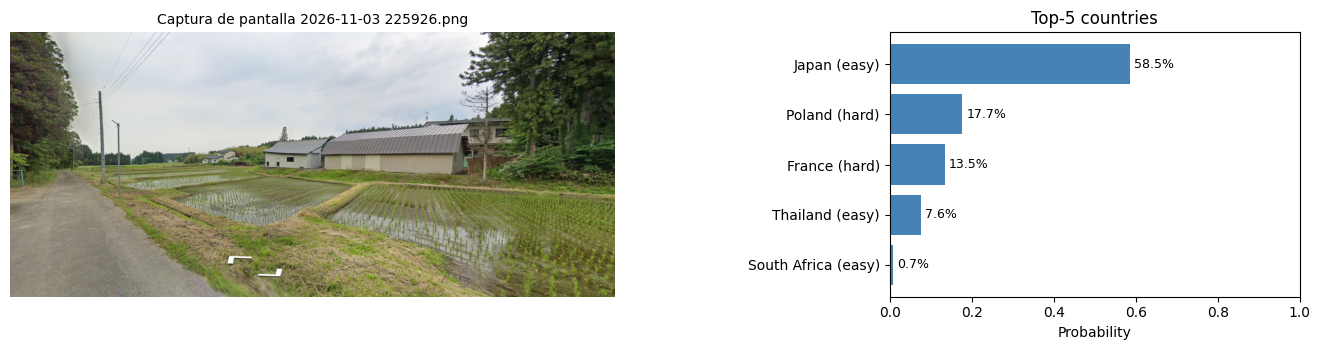

In [5]:
uploaded = files.upload()

for name, data in uploaded.items():
    path = f'/content/{name}'
    with open(path, 'wb') as f:
        f.write(data)
    img, top_k = predict(Image.open(path))
    print(f'{name}: {top_k[0][0]} ({top_k[0][1]:.1%})')
    show_prediction(img, top_k, title=name)

## Console version

The same prediction from a file path, printed as text.

In [6]:
def predict_path(path, k=5):
    _, top_k = predict(Image.open(path), k)
    print(f'Image: {path}')
    for rank, (country, p) in enumerate(top_k, 1):
        print(f'  {rank}. {country:<15} {p:6.1%}')

if uploaded:
    predict_path(f'/content/{next(iter(uploaded))}')

Image: /content/Captura de pantalla 2026-11-03 225926.png
  1. Japan            58.5%
  2. Poland           17.7%
  3. France           13.5%
  4. Thailand          7.6%
  5. South Africa      0.7%


## Optional: web interface with Gradio

A small web page to drag and drop images.

In [7]:
RUN_GRADIO = False

if RUN_GRADIO:
    !pip install -q gradio
    import gradio as gr

    def gradio_predict(img):
        _, top_k = predict(img, k=5)
        return {country: p for country, p in top_k}

    demo = gr.Interface(fn=gradio_predict,
                        inputs=gr.Image(type='pil', label='Street View image or GeoGuessr screenshot'),
                        outputs=gr.Label(num_top_classes=5, label='Most likely countries'),
                        title='PlonkNet-10: which country is this?')
    demo.launch(share=True)
else:
    print('Gradio interface skipped (RUN_GRADIO = False).')

Gradio interface skipped (RUN_GRADIO = False).


In [10]:
import os
import re
import pandas as pd
from PIL import Image

IMAGES_DIR = f'{DRIVE_ROOT}/Inputs_trials/demo_00'

CODE_TO_COUNTRY = {
    'us': 'United States', 'usa': 'United States',
    'jp': 'Japan', 'jpn': 'Japan',
    'br': 'Brazil', 'bra': 'Brazil',
    'za': 'South Africa', 'zaf': 'South Africa', 'sa': 'South Africa',
    'th': 'Thailand', 'tha': 'Thailand',
    'fr': 'France', 'fra': 'France',
    'es': 'Spain', 'esp': 'Spain',
    'pl': 'Poland', 'pol': 'Poland',
    'it': 'Italy', 'ita': 'Italy',
    'de': 'Germany', 'deu': 'Germany', 'ger': 'Germany', 'ge': 'Germany'
}

if not os.path.exists(IMAGES_DIR):
    print(f"Warning: the folder does not exist: {IMAGES_DIR}")
    print("Create the folder in Google Drive or change IMAGES_DIR.")
    image_files = []
else:
    image_files = [f for f in os.listdir(IMAGES_DIR) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    print(f"Found {len(image_files)} images in the folder.")

if image_files:
    rows = []
    for name in image_files:
        path = os.path.join(IMAGES_DIR, name)

        prefix_match = re.match(r'[A-Za-z]+', name)
        prefix = prefix_match.group(0).lower() if prefix_match else 'unknown'
        true_country = CODE_TO_COUNTRY.get(prefix, 'unknown')


        _, top_k = predict(Image.open(path))
        top_names = [c for c, _ in top_k]

        rows.append({
            'file': name,
            'true': true_country,
            'predicted': top_names[0],
            'confidence': round(top_k[0][1], 3),
            'top1_correct': top_names[0] == true_country,
            'in_top5': true_country in top_names
        })

    demo = pd.DataFrame(rows).sort_values('file')
    display(demo)
    print(f"\nTop-1: {demo['top1_correct'].mean():.0%} | Top-5: {demo['in_top5'].mean():.0%} ({len(demo)} images)")

    output_csv = f'{DRIVE_ROOT}/Outputs/demo_predictions_20.csv'
    demo.to_csv(output_csv, index=False)
    print(f"Results saved to: {output_csv}")

Found 20 images in the folder.


,file,true,predicted,confidence,top1_correct,in_top5
2,BR_00.png,Brazil,Brazil,0.797,True,True
3,BR_01.png,Brazil,Brazil,0.602,True,True
12,ES_00.png,Spain,South Africa,0.703,False,True
13,ES_01.png,Spain,South Africa,0.413,False,True
10,FR_00.png,France,France,0.613,True,True
11,FR_01.png,France,France,0.372,True,True
18,GE_00.png,Germany,United States,0.594,False,True
19,GE_01.png,Germany,France,0.450,False,True
16,IT_00.png,Italy,France,0.537,False,True
17,IT_01.png,Italy,France,0.857,False,True



Top-1: 55% | Top-5: 100% (20 images)
Results saved to: /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/demo_predictions_20.csv
